# Study 2 (satellite cybersecurity): main analysis

Writes tables to `tables/` and figures to `plots/`. The manuscript, and `study_comparison/study_comparison.ipynb`, read those files.

**Input:** `data/clean/analysis_data.csv`, produced by `get_data.py`.

## Setup

Moves into this folder, then loads the shared helpers and utility functions.

In [1]:
# Every path in this notebook is relative to the satellite/ folder. Move there first, so the
# notebook runs whether the kernel starts in satellite/ or in the repo root.
import os
from pathlib import Path
if not Path("hte_grf.R").exists() and Path("satellite/hte_grf.R").exists():
    os.chdir("satellite")

import sys, os
sys.path.insert(0, os.path.abspath('.'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import ttest_ind, spearmanr
import math, re

from helpers import (
    make_aesthetic, cat_stats, array_stats, clean_vars,
    cat_stats_table, age_bands, format_p_value, format_p_value_stars,
    add_stars_to_df,
)
from statsmodels_handler import StatsmodelsHandler

####################
# Utility functions
####################

def z_score(series):
    return (series - series.mean()) / series.std(ddof=0)

def cohens_d(group_a, group_b):
    group_a, group_b = group_a.dropna(), group_b.dropna()
    n_a, n_b = len(group_a), len(group_b)
    if n_a < 2 or n_b < 2:
        return np.nan
    sd_a, sd_b = group_a.std(ddof=1), group_b.std(ddof=1)
    pooled_sd = np.sqrt(((n_a - 1)*sd_a**2 + (n_b - 1)*sd_b**2) / (n_a + n_b - 2))
    return (group_a.mean() - group_b.mean()) / pooled_sd

def bootstrap_cohens_d_se(group_a, group_b, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    a, b = group_a.dropna().values, group_b.dropna().values
    if len(a) < 2 or len(b) < 2:
        return np.nan
    boot_ds = [
        cohens_d(pd.Series(rng.choice(a, len(a), replace=True)),
                 pd.Series(rng.choice(b, len(b), replace=True)))
        for _ in range(n_boot)
    ]
    return np.std(boot_ds, ddof=1)

def extract_number(value):
    if pd.isna(value):
        return np.nan
    m = re.search(r"-?\d+(\\.\d+)?", str(value))
    return float(m.group()) if m else np.nan

def fisher_spearman_ci(rho, n, z=1.96):
    stderr = 1.0 / math.sqrt(n - 3)
    delta = z * stderr
    return math.tanh(math.atanh(rho) - delta), math.tanh(math.atanh(rho) + delta)

####################
# Load clean data (run get_data.py first if needed)
####################

LOW_FAM_CUTOFF = 2

df = pd.read_csv("data/clean/analysis_data.csv")
# ac_prop_ai_words exceeds 1 for a handful of participants; cap it so the
# proportion is well defined wherever it is used downstream.
if "ac_prop_ai_words" in df.columns:
    df["ac_prop_ai_words"] = df["ac_prop_ai_words"].clip(upper=1)


print(f"\nN = {len(df)}")
print(f"treat_status:\n{df['treat_status'].value_counts().to_string()}")
low_n = (df['familiar'] <= LOW_FAM_CUTOFF).sum()
print(f"\nLow familiarity (familiar <= {LOW_FAM_CUTOFF}): {low_n} / {len(df)} ({100*low_n/len(df):.1f}%)")
print(f"High familiarity: {len(df)-low_n} / {len(df)} ({100*(len(df)-low_n)/len(df):.1f}%)")


N = 894
treat_status:
treat_status
vignette    303
treat       298
placebo     293

Low familiarity (familiar <= 2): 425 / 894 (47.5%)
High familiarity: 469 / 894 (52.5%)


## Load data

**Input:** `data/clean/analysis_data.csv`. Caps `ac_prop_ai_words` at 1.

In [2]:
df = pd.read_csv("data/clean/analysis_data.csv")
# ac_prop_ai_words exceeds 1 for a handful of participants; cap it so the
# proportion is well defined wherever it is used downstream.
if "ac_prop_ai_words" in df.columns:
    df["ac_prop_ai_words"] = df["ac_prop_ai_words"].clip(upper=1)

# Treatment effects

## Subsamples

**Computation:** restricts to the three arms and defines the full and familiarity subsamples used below.

In [3]:
####################
# Subsamples (used throughout)
####################



KNOWN_ARMS = ["treat", "vignette", "placebo"]
df = df[df["treat_status"].isin(KNOWN_ARMS)].copy()

subsamples = {
    "Full Sample":    df.copy(),
    "Low Knowledge":  df[df["familiar"] <= LOW_FAM_CUTOFF].copy(),
    "High Knowledge": df[df["familiar"] >  LOW_FAM_CUTOFF].copy(),
}
for sdf in subsamples.values():
    sdf["treat_status"] = pd.Categorical(
        sdf["treat_status"], categories=["treat", "vignette", "placebo"]
    )

OUTCOMES = {
    "distance_index": "Psychological Closeness",
    "attitude_index": "Policy Attitudes",
}
COND_LABELS = {"treat": "AIM", "vignette": "Vignette", "placebo": "Placebo"}
CONTRASTS = {
    "C(treat_status)[T.vignette]": "AIM vs. Vignette",
    "C(treat_status)[T.placebo]": "AIM vs. Placebo",
}

## Main effects

**Computation:** AIM-minus-control effects on closeness and attitudes, overall and by familiarity, with sharpened q-values over the 12 contrasts at each cutoff.


CUTOFF=2  SAMPLE: Full Sample  (N=894)

  Psychological Closeness  |  R2=0.133  N=894
  AIM vs. Vignette: beta=0.38, SE=0.07, 95% CI [0.24, 0.51], t=-5.47, p = 4.5e-08, sharpened q=0.001, 4.548950974931647e-08
  AIM vs. Placebo: beta=0.90, SE=0.08, 95% CI [0.74, 1.05], t=-11.55, p = 7.8e-31, sharpened q=0.001, 7.799276791309273e-31

  Policy Attitudes  |  R2=0.084  N=894
  AIM vs. Vignette: beta=0.54, SE=0.08, 95% CI [0.39, 0.69], t=-7.06, p = 1.7e-12, sharpened q=0.001, 1.7170954390474792e-12
  AIM vs. Placebo: beta=0.67, SE=0.08, 95% CI [0.52, 0.82], t=-8.75, p = 2.2e-18, sharpened q=0.001, 2.1758698817188184e-18

CUTOFF=2  SAMPLE: Low Knowledge  (N=425)

  Psychological Closeness  |  R2=0.205  N=425
  AIM vs. Vignette: beta=0.40, SE=0.11, 95% CI [0.19, 0.62], t=-3.73, p = 1.9e-04, sharpened q=0.001, 0.0001921547138521863
  AIM vs. Placebo: beta=1.22, SE=0.12, 95% CI [0.98, 1.46], t=-10.13, p = 4.0e-24, sharpened q=0.001, 4.033990921113683e-24

  Policy Attitudes  |  R2=0.130  N=425

/var/folders/4r/zf8yg_9n3qn26k_y7w56_gqr0000gp/T/ipykernel_47705/1373738474.py:148: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.2, wspace=0.25, hspace=0.30)


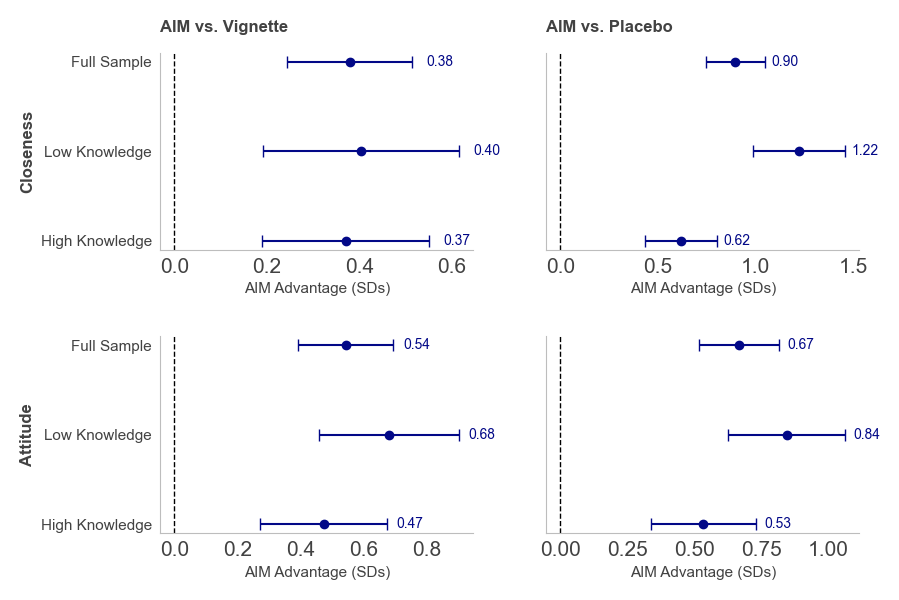


CUTOFF=3  SAMPLE: Full Sample  (N=894)

  Psychological Closeness  |  R2=0.133  N=894
  AIM vs. Vignette: beta=0.38, SE=0.07, 95% CI [0.24, 0.51], t=-5.47, p = 4.5e-08, sharpened q=0.001, 4.548950974931647e-08
  AIM vs. Placebo: beta=0.90, SE=0.08, 95% CI [0.74, 1.05], t=-11.55, p = 7.8e-31, sharpened q=0.001, 7.799276791309273e-31

  Policy Attitudes  |  R2=0.084  N=894
  AIM vs. Vignette: beta=0.54, SE=0.08, 95% CI [0.39, 0.69], t=-7.06, p = 1.7e-12, sharpened q=0.001, 1.7170954390474792e-12
  AIM vs. Placebo: beta=0.67, SE=0.08, 95% CI [0.52, 0.82], t=-8.75, p = 2.2e-18, sharpened q=0.001, 2.1758698817188184e-18

CUTOFF=3  SAMPLE: Low Knowledge  (N=584)

  Psychological Closeness  |  R2=0.169  N=584
  AIM vs. Vignette: beta=0.39, SE=0.09, 95% CI [0.21, 0.57], t=-4.28, p = 1.9e-05, sharpened q=0.001, 1.8963733413902355e-05
  AIM vs. Placebo: beta=1.05, SE=0.10, 95% CI [0.86, 1.24], t=-10.92, p = 9.2e-28, sharpened q=0.001, 9.213881390401615e-28

  Policy Attitudes  |  R2=0.106  N=58

/var/folders/4r/zf8yg_9n3qn26k_y7w56_gqr0000gp/T/ipykernel_47705/1373738474.py:148: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.2, wspace=0.25, hspace=0.30)


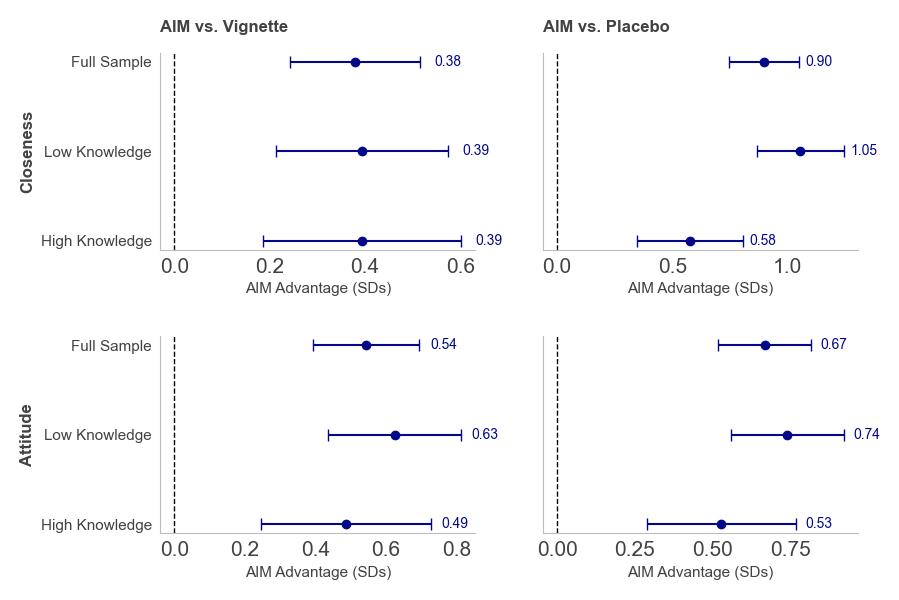

In [4]:
from sharp_q_values import compute_q
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np

SHOW_RAW_DIFF = False

OUTCOME_LABELS = {
    "distance_index": "Psychological Closeness",
    "attitude_index": "Policy Attitudes",
}
OUTCOME_SHORT = {
    "distance_index": "Closeness",
    "attitude_index": "Attitude",
}
CONTRASTS = {
    "C(treat_status)[T.vignette]": "AIM vs. Vignette",
    "C(treat_status)[T.placebo]": "AIM vs. Placebo",
}
SAMPLE_ORDER = ["Full Sample", "Low Knowledge", "High Knowledge"]

for LOW_FAM_CUTOFF in [2, 3]:

    local_subsamples = {
        "Full Sample":    df.copy(),
        "Low Knowledge":  df[df["familiar"] <= LOW_FAM_CUTOFF].copy(),
        "High Knowledge": df[df["familiar"] >  LOW_FAM_CUTOFF].copy(),
    }
    for sdf in local_subsamples.values():
        sdf["treat_status"] = pd.Categorical(
            sdf["treat_status"], categories=["treat", "vignette", "placebo"]
        )

    results = {}
    for name, sdf in local_subsamples.items():
        results[name] = {}
        for outcome in ["distance_index", "attitude_index"]:
            results[name][outcome] = smf.ols(
                f"{outcome} ~ C(treat_status)", data=sdf
            ).fit(cov_type="HC1")

    ###############
    # Sharpened q-values: the 12 contrasts at this cutoff (3 samples x 2 outcomes x 2 controls) are one family
    ###############

    q_keys = [(s, o, r) for s, outcome_models in results.items()
              for o, m in outcome_models.items() for r in CONTRASTS if r in m.params.index]
    q_sharp = dict(zip(q_keys, compute_q(np.array([results[s][o].pvalues[r] for s, o, r in q_keys]))))

    for sample_name, outcome_dict in results.items():
        n = len(local_subsamples[sample_name])
        print(f"\n{'='*65}")
        print(f"CUTOFF={LOW_FAM_CUTOFF}  SAMPLE: {sample_name}  (N={n})")
        print(f"{'='*65}")
        for outcome, mod in outcome_dict.items():
            print(f"\n  {OUTCOME_LABELS[outcome]}  |  R2={mod.rsquared:.3f}  N={int(mod.nobs)}")
            for raw_name, label in CONTRASTS.items():
                if raw_name not in mod.params.index:
                    continue
                beta   = -mod.params[raw_name]
                se     =  mod.bse[raw_name]
                t_stat =  mod.tvalues[raw_name]
                pval   =  mod.pvalues[raw_name]
                ci     =  mod.conf_int().loc[raw_name]
                ci_lo, ci_hi = -ci[1], -ci[0]
                p_str = format_p_value(pval)
                print(
                    f"  {label}: beta={beta:.2f}, SE={se:.2f}, "
                    f"95% CI [{ci_lo:.2f}, {ci_hi:.2f}], t={t_stat:.2f}, {p_str}, "
                    f"sharpened q={q_sharp[(sample_name, outcome, raw_name)]:.3f}, {pval}"
                )

    ###############
    # Forest plot
    ###############

    forest_rows = []
    for sample_name in SAMPLE_ORDER:
        for outcome, mod in results[sample_name].items():
            if outcome not in OUTCOME_SHORT:
                continue
            for raw_name, contrast_label in CONTRASTS.items():
                if raw_name not in mod.params.index:
                    continue
                beta = -mod.params[raw_name]
                ci = mod.conf_int().loc[raw_name]
                forest_rows.append({
                    "sample":   sample_name,
                    "outcome":  OUTCOME_SHORT[outcome],
                    "contrast": contrast_label,
                    "beta":     beta,
                    "ci_lo":    -ci[1],
                    "ci_hi":    -ci[0],
                    "sig":      mod.pvalues[raw_name] < 0.05,
                    "kind":     "Regression-based",
                })
    forest_df = pd.DataFrame(forest_rows)

    pal = make_aesthetic()
    contrasts = list(CONTRASTS.values())
    outcomes  = list(OUTCOME_SHORT.values())

    fig, axes = plt.subplots(len(outcomes), len(contrasts), figsize=(9, 6), sharey=True)
    axes = np.atleast_2d(axes)

    y_ticks = {"High Knowledge": 0, "Low Knowledge": 1, "Full Sample": 2}
    y_labels = ["High Knowledge", "Low Knowledge", "Full Sample"]
    _sig_color   = "#020887"
    _insig_color = "#2E2E2E"
    _markers = {"Regression-based": "o", "Raw difference": "D"}
    _kinds = forest_df["kind"].unique().tolist()
    _dodge = {k: (i - (len(_kinds)-1)/2) * 0.18 for i, k in enumerate(_kinds)}

    for row_i, outcome in enumerate(outcomes):
        for col_i, contrast in enumerate(contrasts):
            ax = axes[row_i, col_i]
            subset = forest_df[
                (forest_df["outcome"] == outcome) &
                (forest_df["contrast"] == contrast)
            ]
            for _, r in subset.iterrows():
                y    = y_ticks[r["sample"]] + _dodge.get(r["kind"], 0)
                col  = _sig_color if r["sig"] else _insig_color
                mrkr = _markers.get(r["kind"], "o")
                ax.errorbar(
                    r["beta"], y,
                    xerr=[[r["beta"] - r["ci_lo"]], [r["ci_hi"] - r["beta"]]],
                    fmt=mrkr, color=col, ecolor=col, capsize=4, markersize=6, linewidth=1.5,
                )
                if r["kind"] == "Regression-based":
                    ax.text(
                        r["ci_hi"] + 0.03, y, f"{r['beta']:.2f}",
                        va="center", ha="left", fontsize=10, color=col,
                    )
            ax.axvline(0, color="black", linestyle="--", linewidth=1)
            ax.set_yticks([0, 1, 2])
            if col_i == 0:
                ax.set_yticklabels(y_labels, fontsize=11)
                ax.set_ylabel(outcome, fontsize=12, fontweight="bold")
            else:
                ax.tick_params(labelleft=False)
                ax.set_ylabel("")
            ax.set_xlabel("AIM Advantage (SDs)", fontsize=11)
            if row_i == 0:
                ax.set_title(contrast, fontsize=12, fontweight="bold")
            ax.spines[["top", "right"]].set_visible(False)

    plt.subplots_adjust(left=0.2, wspace=0.25, hspace=0.30)
    fig.savefig(f"plots/forest_plot_{LOW_FAM_CUTOFF}.pdf", bbox_inches="tight")
    plt.show()

## Covariate-adjusted main effects

**Computation:** the main effects re-estimated with pretreatment covariates.

In [5]:
####################
# Build covariate indicators
####################

if "pid3" in df.columns:
    df["is_republican"] = (df["pid3"].astype(str).str.lower() == "republican").astype(float)
    df["is_democrat"]   = (df["pid3"].astype(str).str.lower() == "democrat").astype(float)
else:
    df["is_republican"] = np.nan
    df["is_democrat"]   = np.nan

if "demo_gender" in df.columns:
    df["is_male"] = df["demo_gender"].str.strip().str.lower().isin(["male", "man"]).astype(float)
else:
    df["is_male"] = np.nan

COVARIATES = [
    "familiar", "age", "educ_num", "income_num",
    "mi_index", "iri_fa", "iri_pc", "iri_pd",
    "rw_journal", "rw_write", "ai_attitude_index",
    "is_republican", "is_democrat", "is_male",
]
if "ideology_num" in df.columns:
    COVARIATES.append("ideology_num")

cov_str = " + ".join(COVARIATES)

for LOW_FAM_CUTOFF in [2, 3]:
    local_subsamples = {
        "Full Sample":    df.copy(),
        "Low Knowledge":  df[df["familiar"] <= LOW_FAM_CUTOFF].copy(),
        "High Knowledge": df[df["familiar"] >  LOW_FAM_CUTOFF].copy(),
    }
    for sdf in local_subsamples.values():
        sdf["treat_status"] = pd.Categorical(
            sdf["treat_status"], categories=["treat", "vignette", "placebo"]
        )

    print(f"\n{'='*65}  CUTOFF={LOW_FAM_CUTOFF}")
    for sample_name, sdf in local_subsamples.items():
        n = len(sdf)
        print(f"\n  SAMPLE: {sample_name}  (N={n})")
        for outcome in ["distance_index", "attitude_index"]:
            formula = f"{outcome} ~ C(treat_status) + {cov_str}"
            try:
                mod = smf.ols(formula, data=sdf).fit(cov_type="HC1")
            except Exception as e:
                print(f"    {outcome}: ERROR — {e}")
                continue
            print(f"    {OUTCOME_LABELS.get(outcome, outcome)}  R2={mod.rsquared:.3f}  N={int(mod.nobs)}")
            for raw_name, label in CONTRASTS.items():
                if raw_name not in mod.params.index:
                    continue
                beta   = -mod.params[raw_name]
                se     =  mod.bse[raw_name]
                t_stat =  mod.tvalues[raw_name]
                pval   =  mod.pvalues[raw_name]
                ci     =  mod.conf_int().loc[raw_name]
                ci_lo, ci_hi = -ci[1], -ci[0]
                p_str = format_p_value(pval)
                print(
                    f"      {label}: beta={beta:.2f}, SE={se:.2f}, "
                    f"95% CI [{ci_lo:.2f}, {ci_hi:.2f}], t={t_stat:.2f}, {p_str}"
                )


=================================================================  CUTOFF=2

  SAMPLE: Full Sample  (N=894)
    Psychological Closeness  R2=0.320  N=873
      AIM vs. Vignette: beta=0.43, SE=0.07, 95% CI [0.30, 0.56], t=-6.41, p = 1.5e-10
      AIM vs. Placebo: beta=0.90, SE=0.07, 95% CI [0.75, 1.04], t=-12.32, p = 6.8e-35
    Policy Attitudes  R2=0.300  N=873
      AIM vs. Vignette: beta=0.61, SE=0.07, 95% CI [0.47, 0.75], t=-8.47, p = 2.4e-17
      AIM vs. Placebo: beta=0.68, SE=0.07, 95% CI [0.54, 0.81], t=-9.80, p = 1.1e-22

  SAMPLE: Low Knowledge  (N=425)
    Psychological Closeness  R2=0.374  N=413
      AIM vs. Vignette: beta=0.54, SE=0.11, 95% CI [0.33, 0.75], t=-4.97, p = 6.7e-07
      AIM vs. Placebo: beta=1.24, SE=0.12, 95% CI [1.01, 1.47], t=-10.66, p = 1.6e-26
    Policy Attitudes  R2=0.309  N=413
      AIM vs. Vignette: beta=0.79, SE=0.11, 95% CI [0.57, 1.02], t=-6.92, p = 4.7e-12
      AIM vs. Placebo: beta=0.87, SE=0.11, 95% CI [0.66, 1.08], t=-8.21, p = 2.3e-16

  SA

## Familiarity moderation

**Output:** `satellite_familiarity_moderation.csv`

**Computation:** the preregistered moderation test, `outcome ~ (is_vignette + is_placebo) * low` with HC1 standard errors, at both familiarity cutoffs (low = familiarity at or below the cutoff). Each estimate is the additional AIM-minus-control effect among low-familiarity participants (the interaction coefficient with its sign reversed). Sharpened q-values treat the eight tests (2 outcomes x 2 controls x 2 cutoffs) as one family.

In [6]:
####################
# Familiarity moderation: preregistered condition x low-familiarity interactions
####################
from sharp_q_values import compute_q

MODERATION_OUTCOMES = {"closeness_index": "Closeness", "attitude_index": "Attitudes"}
moderation_df = df.assign(is_vignette=df.treat_status.eq("vignette").astype(int),
                          is_placebo=df.treat_status.eq("placebo").astype(int))

rows = []
for cutoff in [2, 3]:
    d = moderation_df.assign(low=(moderation_df.familiar <= cutoff).astype(float).where(moderation_df.familiar.notna()))
    for outcome, label in MODERATION_OUTCOMES.items():
        fit = smf.ols(f"{outcome} ~ (is_vignette + is_placebo) * low", data=d).fit(cov_type="HC1")
        for control in ["vignette", "placebo"]:
            term = f"is_{control}:low"
            ci = fit.conf_int().loc[term]
            rows.append({"cutoff": cutoff, "outcome": label, "control": control,
                         "b": -fit.params[term], "lo": -ci[1], "hi": -ci[0], "p": fit.pvalues[term],
                         "n": int(fit.nobs)})

moderation = pd.DataFrame(rows)
moderation["q"] = compute_q(moderation.p.values)
moderation.to_csv("tables/satellite_familiarity_moderation.csv", index=False)
for r in moderation.itertuples():
    print(f"Cutoff <= {r.cutoff}, {r.outcome}, AIM vs {r.control}: additional effect among low familiarity "
          f"b={r.b:.2f}, 95% CI [{r.lo:.2f}, {r.hi:.2f}], {format_p_value(r.p)}, sharpened q={r.q:.3f}")

Cutoff <= 2, Closeness, AIM vs vignette: additional effect among low familiarity b=0.03, 95% CI [-0.25, 0.31], p = .81, sharpened q=0.537
Cutoff <= 2, Closeness, AIM vs placebo: additional effect among low familiarity b=0.60, 95% CI [0.30, 0.90], p = 8.1e-05, sharpened q=0.001
Cutoff <= 2, Attitudes, AIM vs vignette: additional effect among low familiarity b=0.21, 95% CI [-0.09, 0.51], p = .18, sharpened q=0.215
Cutoff <= 2, Attitudes, AIM vs placebo: additional effect among low familiarity b=0.31, 95% CI [0.02, 0.60], p = .04, sharpened q=0.083
Cutoff <= 3, Closeness, AIM vs vignette: additional effect among low familiarity b=-0.00, 95% CI [-0.28, 0.27], p = 1.00, sharpened q=0.599
Cutoff <= 3, Closeness, AIM vs placebo: additional effect among low familiarity b=0.48, 95% CI [0.18, 0.78], p = .00, sharpened q=0.006
Cutoff <= 3, Attitudes, AIM vs vignette: additional effect among low familiarity b=0.14, 95% CI [-0.17, 0.44], p = .37, sharpened q=0.395
Cutoff <= 3, Attitudes, AIM vs pla

## Balance

**Output:** `tab:balance.tex`

**Computation:** pretreatment covariates by condition, with sharpened q-values.

In [4]:
from scipy.stats import f_oneway, chi2_contingency
import statsmodels.formula.api as smf
from sharp_q_values import compute_q

####################
# Balance table — pre-treatment covariates by condition
# Continuous vars: one-way ANOVA F-test
# Binary/categorical: chi-square
####################

BALANCE_VARS = {
    'age':               ('Age',                       'continuous'),
    'gender_male':       ('Male (\\%)',                  'binary'),
    'educ_num':          ('Education (Recoded 1–8)',    'continuous'),
    'income_num':        ('Income (Recoded 1–7)',       'continuous'),
    'ideology_num':      ('Political Ideology (+ = conservative)', 'continuous'),
    'familiar':          ('Familiarity w/ satellite cybersecurity','continuous'),
    'mi_index':          ('Mental imagery',             'continuous'),
    'iri_fa':            ('IRI Fantasy',                'continuous'),
    'iri_pc':            ('IRI Perspective-taking',     'continuous'),
    'iri_pd':            ('IRI Personal distress',      'continuous'),
    'rw_write':          ('Creative writing exp.',      'continuous'),
    'rw_journal':        ('Journaling freq.',           'continuous'),
    'ai_attitude_index': ('AI attitudes',               'continuous'),
}

conditions = ['treat', 'placebo', 'vignette']
rows = []

for col, (label, kind) in BALANCE_VARS.items():
    groups = [df[df['treat_status'] == c][col].dropna() for c in conditions]
    means  = [g.mean() for g in groups]
    sds    = [g.std()  for g in groups]

    if kind == 'binary':
        cell_vals = [f"{g.mean()*100:.1f}\\%" for g in groups]
        # chi-square on counts
        ct = pd.crosstab(df[col], df['treat_status'])
        chi2, p, *_ = chi2_contingency(ct)
        stat_str = f"$\\chi^2$={chi2:.2f}"
    else:
        cell_vals = [f"{m:.2f} ({s:.2f})" for m, s in zip(means, sds)]
        F, p = f_oneway(*groups)
        stat_str = f"F={F:.2f}"

    rows.append({
        'Variable': label,
        'Treat':    cell_vals[0],
        'Placebo':  cell_vals[1],
        'Vignette': cell_vals[2],
        'Test':     stat_str,
        'p':        round(p, 3),
    })

# Party ID comes from Prolific supplementary data, so it is missing for participants without it.
# One row with the share of Democrats / Independents / Republicans in each arm, and one
# chi-square test on the full party-by-arm table among participants with party available.
PARTIES = ['Democrat', 'Independent', 'Republican']
party_df = df.dropna(subset=['pid3'])
party_ct = pd.crosstab(party_df['pid3'], party_df['treat_status']).loc[PARTIES, conditions]
chi2, p, *_ = chi2_contingency(party_ct)
rows.append({
    'Variable': 'Party ID: D / I / R (\\%)',
    'Treat':    ' / '.join(f"{100 * party_ct.loc[k, 'treat'] / party_ct['treat'].sum():.1f}" for k in PARTIES),
    'Placebo':  ' / '.join(f"{100 * party_ct.loc[k, 'placebo'] / party_ct['placebo'].sum():.1f}" for k in PARTIES),
    'Vignette': ' / '.join(f"{100 * party_ct.loc[k, 'vignette'] / party_ct['vignette'].sum():.1f}" for k in PARTIES),
    'Test':     f"$\\chi^2$={chi2:.2f}",
    'p':        round(p, 3),
})
n_no_party = int(df['pid3'].isna().sum())

bal_df = pd.DataFrame(rows)
bal_df['q'] = compute_q(bal_df['p'].values)
bal_df['q_str'] = bal_df['q'].map('{:.3f}'.format)

display(bal_df[['Variable','Treat','Placebo','Vignette','Test','q_str']].rename(columns={'q_str':'q'}))

n_sig_p = (bal_df['p'] < .05).sum()
n_sig_q = (bal_df['q'] < .05).sum()
print(f"\n{n_sig_p}/{len(bal_df)} significant at p < .05 | {n_sig_q}/{len(bal_df)} after sharpened q correction (expected ~{len(bal_df)*0.05:.1f} by chance)")

# Save
_bal_out = bal_df[['Variable','Treat','Placebo','Vignette','Test','q_str']].rename(columns={'q_str':'q'})
with open('tables/tab:balance.tex', 'w') as f:
    f.write(
        '\\begin{table}\n'
        '\\caption{Study 2 (satellite cybersecurity) participant descriptives by arm: pre-treatment covariates (M (SD) for continuous; \\% for binary). One-way ANOVA $F$-tests for continuous variables; $\\chi^2$ for binary. Party ID (Democrat / Independent / Republican) is a $\\chi^2$ test on participants with Prolific party data, missing for ' + str(n_no_party) + ' participants. $q$ is the sharpened false-discovery-rate $q$ value, correcting for multiple comparisons across covariates.}\n'
        '\\label{tab:balance_satellite}\n'
        + _bal_out.to_latex(index=False, column_format='llllll')
        + '\\end{table}\n'
    )
print('Wrote tables/tab:balance.tex')


,Variable,Treat,Placebo,Vignette,Test,q
0,Age,45.81 (15.23),45.61 (14.65),47.29 (14.36),F=1.17,0.329
1,Male (\%),40.9\%,46.8\%,49.2\%,$\chi^2$=4.33,0.221
2,Education (Recoded 1–8),3.27 (1.13),3.22 (1.10),3.18 (1.04),F=0.48,0.567
3,Income (Recoded 1–7),4.29 (1.89),4.10 (1.81),3.87 (1.86),F=3.78,0.133
4,Political Ideology (+ = conservative),3.56 (1.72),3.83 (1.76),3.82 (1.85),F=2.21,0.221
5,Familiarity w/ satellite cybersecurity,2.72 (1.60),2.80 (1.51),3.05 (1.55),F=3.72,0.133
6,Mental imagery,8.58 (1.42),8.57 (1.49),8.65 (1.39),F=0.26,0.712
7,IRI Fantasy,3.80 (0.87),3.69 (0.86),3.73 (0.94),F=1.15,0.329
8,IRI Perspective-taking,3.86 (0.87),3.92 (0.83),3.95 (0.86),F=0.87,0.416
9,IRI Personal distress,2.61 (0.96),2.44 (0.93),2.53 (0.95),F=2.40,0.221



3/14 significant at p < .05 | 0/14 after sharpened q correction (expected ~0.7 by chance)
Wrote tables/tab:balance.tex


# Manuscript tables

**Outputs:** `satellite_cfa.tex`, `satellite_sensitivity.tex`, `satellite_subscales.tex` (Supplementary Information)

**Computation:** the preregistered one- versus three-factor comparison of the attitude items, the screening-record sensitivity analysis, and the secondary attitude subscales.

In [7]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-08

Description: Export preregistered satellite measurement checks and secondary effects.

Inputs:
- data/clean/analysis_data.csv: Cleaned satellite responses.

Outputs:
- ../satellite/tables/satellite_cfa.csv
- ../satellite/tables/satellite_subscales.tex
- Aggregate participant checks in notebook output.
"""
from pathlib import Path
import pandas as pd
import semopy
import statsmodels.formula.api as smf

def table_p_latex(value):
    """Retain three significant digits and render probabilities in LaTeX."""
    formatted = f"{value:.3g}"
    if "e" in formatted:
        mantissa, exponent = formatted.split("e")
        return rf"${mantissa}\times10^{{{int(exponent)}}}$"
    if formatted.startswith("0."):
        formatted = formatted[1:]
    return "$" + formatted + "$"

report_data = pd.read_csv("data/clean/analysis_data.csv")
# ac_prop_ai_words exceeds 1 for a handful of participants; cap it so the
# proportion is well defined wherever it is used downstream.
if "ac_prop_ai_words" in report_data.columns:
    report_data["ac_prop_ai_words"] = report_data["ac_prop_ai_words"].clip(upper=1)
report_data = report_data[report_data.treat_status.isin(["treat", "vignette", "placebo"])].copy()
report_dir = Path("../satellite/tables")
report_dir.mkdir(parents=True, exist_ok=True)
attitude_items = {
    "importance": ["dv_at_imp_personal_3", "dv_at_imp_compare_3"],
    "spending": ["dv_at_spend_reduce_3", "dv_at_spend_priority_3"],
    "action": ["dv_at_action_action_3", "dv_at_action_bill_3", "dv_at_action_oppose_3"],
}
all_items = sum(attitude_items.values(), [])
cfa_data = report_data[all_items].dropna()
cfa_data = (cfa_data - cfa_data.mean()) / cfa_data.std()
specifications = {
    "Three factors": "\n".join(f"{factor} =~ " + " + ".join(items) for factor, items in attitude_items.items()),
    "One factor": "attitude =~ " + " + ".join(all_items),
}
cfa_rows = []
for model_name, specification in specifications.items():
    model = semopy.Model(specification)
    fitted = model.fit(cfa_data)
    assert fitted.success
    fit_stats = semopy.calc_stats(model).iloc[0].to_dict()
    cfa_rows.append({"model": model_name, "n": len(cfa_data), **fit_stats})
cfa_table = pd.DataFrame(cfa_rows)
cfa_table.to_csv(report_dir / "satellite_cfa.csv", index=False)
print(cfa_table.to_string(index=False))
from scipy.stats import chi2
cfa_display = cfa_table[["model", "n", "chi2", "DoF", "CFI", "TLI", "RMSEA"]].copy()
cfa_display["DoF"] = cfa_display["DoF"].astype(int)
cfa_display["p"] = [table_p_latex(chi2.sf(statistic, degrees))
                    for statistic, degrees in zip(cfa_display.chi2, cfa_display.DoF)]
cfa_display = cfa_display.rename(columns={"model": "Model", "n": "$n$", "chi2": r"$\chi^2$", "DoF": "df", "p": "$p$"})
cfa_display.to_latex(report_dir / "satellite_cfa.tex", index=False, escape=False,
                     float_format="%.3f", column_format="lrrrrrrr",
                     caption=r"Satellite attitude measurement models. Confirmatory factor analysis of the seven attitude items ($n=894$).",
                     label="tab:satellite-cfa")
report_data["is_vignette"] = report_data.treat_status.eq("vignette").astype(int)
report_data["is_placebo"] = report_data.treat_status.eq("placebo").astype(int)
rows = []
for subscale in attitude_items:
    fit = smf.ols(f"{subscale}_index ~ is_vignette + is_placebo", data=report_data).fit(cov_type="HC1")
    for control in ["vignette", "placebo"]:
        term = f"is_{control}"
        bounds = -fit.conf_int().loc[term].to_numpy()[::-1]
        rows.append({"Subscale": subscale.title(), "Control": control.title(),
                     "$n$": int(fit.nobs), "$b$": -fit.params[term],
                     "95\\% CI": f"[{bounds[0]:.3f}, {bounds[1]:.3f}]",
                     "$z$": -fit.tvalues[term], "$p$": fit.pvalues[term]})
table = pd.DataFrame(rows)
table.to_csv(report_dir / "satellite_subscales.csv", index=False)
table["$p$"] = table["$p$"].map(table_p_latex)
table.to_latex(report_dir / "satellite_subscales.tex", index=False, escape=False,
               float_format="%.3f", column_format="llrrrrr",
               caption=r"Secondary satellite attitude subscales. AIM-minus-control estimates from three-arm OLS models with HC1-robust intervals and two-sided tests.",
               label="tab:subscales")
for col in ["sys_agency_1", "sys_easy", "sys_fun"]:
    print("Range", col, report_data[col].min(), report_data[col].max())
print("Missing reCAPTCHA:", report_data.Q_RecaptchaScore.isna().sum())
print("Unmatched Prolific:", (~report_data.prolific_matched).sum())
print("Duplicate responses:", report_data.ResponseId.duplicated().sum())
print("AIM/placebo fewer than 20 words:", ((report_data.ac_total_words < 20) & report_data.treat_status.ne("vignette")).sum())
print("Analysis dates:", report_data.StartDate.min(), report_data.StartDate.max())
print("Age mean, SD:", report_data.age.mean(), report_data.age.std())
print("Gender counts:", report_data.demo_gender.value_counts().to_dict())

####################
# Sensitivity to incomplete screening records
####################
sensitivity_samples = {
    "Retained sample": report_data,
    "Prolific-matched": report_data[report_data.prolific_matched],
}
sensitivity_rows = []
for sample_name, subset in sensitivity_samples.items():
    for outcome in ["closeness_index", "attitude_index"]:
        fit = smf.ols(f"{outcome} ~ is_vignette + is_placebo", data=subset).fit(cov_type="HC1")
        for control in ["vignette", "placebo"]:
            term = f"is_{control}"
            lo, hi = -fit.conf_int().loc[term].to_numpy()[::-1]
            sensitivity_rows.append({"Sample": sample_name, "Outcome": outcome.replace("_index", "").title(),
                                     "Control": control.title(), "$n$": int(fit.nobs),
                                     "$b$": -fit.params[term], "95\\% CI": f"[{lo:.3f}, {hi:.3f}]",
                                     "$p$": fit.pvalues[term]})
sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table.to_csv(report_dir / "satellite_sensitivity.csv", index=False)
print(sensitivity_table.to_string(index=False))
sensitivity_table["$p$"] = sensitivity_table["$p$"].map(table_p_latex)
sensitivity_table.to_latex(report_dir / "satellite_sensitivity.tex", index=False, escape=False,
                          float_format="%.3f", column_format="lllrrrr",
                          caption=r"Satellite sensitivity analysis excluding five records without linked Prolific data.",
                          label="tab:sensitivity")

        model   n  DoF  DoF Baseline       chi2  chi2 p-value  chi2 Baseline      CFI      GFI     AGFI      NFI      TLI    RMSEA       AIC        BIC   LogLik
Three factors 894 11.0          21.0 122.583918           0.0    4097.573454 0.972628 0.970084 0.942887 0.970084 0.947744 0.106581 33.725763 115.252761 0.137118
   One factor 894 14.0          21.0 932.935450           0.0    4097.573454 0.774581 0.772320 0.658480 0.772320 0.661872 0.271115 25.912896  93.052777 1.043552
Range sys_agency_1 -3.0 3.0
Range sys_easy 1.0 5.0
Range sys_fun 1.0 7.0
Missing reCAPTCHA: 722
Unmatched Prolific: 5
Duplicate responses: 0
AIM/placebo fewer than 20 words: 0
Analysis dates: 2026-08-21 12:44:11 2026-09-02 12:41:48
Age mean, SD: 46.24439461883408 14.755497823495666
Gender counts: {'Female': 472, 'Male': 408, 'Non-binary / third gender': 9, 'Prefer not to say': 3, 'Prefer to self-describe:': 2}
          Sample   Outcome  Control  $n$      $b$        95\% CI          $p$
 Retained sample Closenes

# Qualitative themes

Theme table for the Study 2 open-text responses, from the BERTopic conservative sweep.
Clusters were transcribed by hand; percentages use substantive clusters only.


## Topic model

BERTopic over the open-text responses with INSTRUCTOR embeddings, at the
conservative sweep. Writes a timestamped summary and the fitted models to
`text_analysis_freeze/`. The theme table below is transcribed from one such run.


In [8]:
# ─────────────────────────────────────────────
# FLAG: EXCLUSION — Qualitative BERTopic analysis
# Sample: treatment arm of app_df only.
# Responses shorter than MIN_TEXT_LENGTH_WORDS words are dropped.
# ─────────────────────────────────────────────

import os
import random
from datetime import datetime

import numpy as np
import pandas as pd

try:
    from bertopic import BERTopic
    from sentence_transformers import SentenceTransformer
    from sklearn.feature_extraction.text import CountVectorizer
    from sklearn.metrics.pairwise import cosine_similarity
    from umap import UMAP
    from hdbscan import HDBSCAN
    _bertopic_available = True
except ImportError:
    _bertopic_available = False
    print("bertopic not installed — skipping qualitative BERTopic analysis")

try:
    import torch
except ImportError:
    torch = None


###############
# Knobs (defaults — overridden per sweep below)
###############

df = pd.read_csv("data/clean/analysis_data.csv")

app_df = df[df['treat_status'].isin(['treat', 'placebo'])].copy()
app_df = app_df.dropna(subset=['ac_received'])

# Canonical adoption column names (mapped from ac_* flat cols)
app_df['n_received']    = app_df['ac_received']
app_df['n_accepted']    = app_df['ac_accepted']
app_df['pct_accepted']  = app_df['ac_acceptance_rate']
app_df['story_words']   = app_df['ac_total_words']
app_df['prop_ai_words'] = app_df['ac_prop_ai_words'].clip(upper=1)

print(f"app_df N = {len(app_df)}")
print(app_df['treat_status'].value_counts().to_string())
print()
for col in ['n_received', 'n_accepted', 'pct_accepted', 'story_words', 'prop_ai_words']:
    print(f"  {col}: M={app_df[col].mean():.2f}, SD={app_df[col].std():.2f}, NaN={app_df[col].isna().sum()}")

TEXT_COLS = {
    "What worked": "why_why_not_pos",
    "What did not work": "why_why_not_neg",
}

TREAT_COL = "treat_status"
TREAT_VALUE = "treat"

MODEL_NAME = "hkunlp/instructor-large"

EMBEDDING_INSTRUCTIONS = {
    "What worked": (
        "Embed this participant response so that we can identify distinct reasons "
        "why a co-writing AI system was effective at reducing psychological distance or changing attitudes towards satellite cybersecurity."
    ),
    "What did not work": (
        "Embed this participant response so that we can identify distinct reasons "
        "why a co-writing AI system failed to reduce psychological distance "
        "or change attitudes towards satellite cybersecurity."
    ),
}

MIN_TEXT_LENGTH_WORDS = 5

MIN_CLUSTER_SIZE = 20
MIN_SAMPLES      = 5
UMAP_N_NEIGHBORS = 15
UMAP_N_COMPONENTS = 5
UMAP_MIN_DIST    = 0.0

VECTORIZER_NGRAM_RANGE = (1, 2)
VECTORIZER_MIN_DF = 2
VECTORIZER_STOP_WORDS = "english"

N_LABEL_WORDS  = 4
N_KEYWORDS     = 8
N_REPRESENTATIVE = 20

RANDOM_STATE = 42

OUTPUT_DIR    = "text_analysis_freeze"
OUTPUT_PREFIX = "bertopic_topic_summary"

# The frozen run the theme table is transcribed from. It is committed, so the model
# only refits when it is absent. Delete it to refit; re-running reproduces it.
FREEZE_RUN  = "20260908_170416"   # Conservative (min_cluster=12, min_samples=6, neighbors=15)
FREEZE_PATH = f"{OUTPUT_DIR}/{OUTPUT_PREFIX}_{FREEZE_RUN}.txt"


###############
# Sweeps
###############

# Looks coherent
SWEEPS = [
    {
        "label": "Conservative (min_cluster=12, min_samples=6, neighbors=15)",
        "min_cluster_size": 12,
        "min_samples": 6,
        "n_neighbors": 15,
    },


]

###############
# Reproducibility
###############

def set_random_seeds(seed=RANDOM_STATE):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


###############
# Main
###############

def run_bertopic_analysis(df, sweep_params=None):
    """Run BERTopic for each question using sweep_params overrides."""
    set_random_seeds(RANDOM_STATE)

    embedding_model = SentenceTransformer(MODEL_NAME, trust_remote_code=True)

    results = {}

    for heading, text_col in TEXT_COLS.items():
        # resolve per-question or global params
        p = sweep_params or {}
        if "params_by_question" in p:
            qp = p["params_by_question"].get(heading, {})
        else:
            qp = p
        min_cluster_size = qp.get("min_cluster_size", MIN_CLUSTER_SIZE)
        min_samples      = qp.get("min_samples",      MIN_SAMPLES)
        n_neighbors      = qp.get("n_neighbors",      UMAP_N_NEIGHBORS)

        topic_df = make_topic_df(df, text_col)
        docs = topic_df["text"].tolist()

        embeddings = embed_texts(
            embedding_model=embedding_model,
            docs=docs,
            instruction=EMBEDDING_INSTRUCTIONS[heading],
        )

        topic_model = make_bertopic_model(min_cluster_size, min_samples, n_neighbors)
        topics, _ = topic_model.fit_transform(docs, embeddings)

        topic_model, topic_label_map = add_topic_labels(topic_model)

        topic_df["topic"] = topics
        topic_df["topic_label"] = topic_df["topic"].map(topic_label_map)

        summary_df = summarize_topics(
            topic_model=topic_model,
            topic_df=topic_df,
            topic_label_map=topic_label_map,
            embeddings=embeddings,
        )

        results[heading] = {
            "text_col": text_col,
            "topic_model": topic_model,
            "topic_label_map": topic_label_map,
            "topic_df": topic_df,
            "summary_df": summary_df,
            "embeddings": embeddings,
            "topics": topics,
        }

    return results


###############
# Data prep
###############

def make_topic_df(df, text_col):
    topic_df = df[[text_col]].copy()
    topic_df = topic_df.rename(columns={text_col: "text"})
    topic_df = topic_df.dropna(subset=["text"])
    topic_df["text"] = topic_df["text"].astype(str).str.strip()
    topic_df = topic_df[topic_df["text"].str.split().str.len() > MIN_TEXT_LENGTH_WORDS]
    return topic_df.reset_index(names="original_index")


###############
# Embeddings
###############

def embed_texts(embedding_model, docs, instruction):
    """Embed using INSTRUCTOR-style instruction pairs."""
    instructed_docs = [[instruction, doc] for doc in docs]
    embeddings = embedding_model.encode(
        instructed_docs,
        normalize_embeddings=True,
        show_progress_bar=True,
    )
    return np.asarray(embeddings)


###############
# BERTopic model
###############

def make_bertopic_model(min_cluster_size, min_samples, n_neighbors):
    vectorizer_model = CountVectorizer(
        stop_words=VECTORIZER_STOP_WORDS,
        ngram_range=VECTORIZER_NGRAM_RANGE,
        min_df=VECTORIZER_MIN_DF,
    )
    umap_model = UMAP(
        n_neighbors=n_neighbors,
        n_components=UMAP_N_COMPONENTS,
        min_dist=UMAP_MIN_DIST,
        metric="cosine",
        random_state=RANDOM_STATE,
    )
    hdbscan_model = HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric="euclidean",
        cluster_selection_method="eom",
        prediction_data=True,
    )
    return BERTopic(
        vectorizer_model=vectorizer_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        nr_topics=None,
        calculate_probabilities=False,
        verbose=False,
    )


###############
# Topic labels
###############

def add_topic_labels(topic_model):
    topic_info = topic_model.get_topic_info()
    topic_label_map = {-1: "Unclustered"}
    for topic_id in topic_info["Topic"]:
        topic_id = int(topic_id)
        if topic_id == -1:
            continue
        words = topic_model.get_topic(topic_id)
        if not words:
            topic_label_map[topic_id] = f"Topic {topic_id}"
            continue
        topic_label_map[topic_id] = " / ".join(w for w, _ in words[:N_LABEL_WORDS])
    topic_model.set_topic_labels(topic_label_map)
    return topic_model, topic_label_map

def get_topic_keywords(topic_model, topic_id):
    words = topic_model.get_topic(topic_id)
    return ", ".join(w for w, _ in words[:N_KEYWORDS]) if words else ""


###############
# Summaries
###############

def summarize_topics(topic_model, topic_df, topic_label_map, embeddings=None):
    topic_info = topic_model.get_topic_info()
    topic_info = topic_info[topic_info["Topic"] != -1].sort_values("Count", ascending=False)

    rows = []
    for _, topic_row in topic_info.iterrows():
        topic_id = int(topic_row["Topic"])
        topic_docs = (
            topic_df[topic_df["topic"].eq(topic_id)]["text"].dropna().tolist()
        )
        # Rank by cosine similarity to centroid
        idxs = topic_df.index[topic_df["topic"].eq(topic_id)].tolist()
        if embeddings is not None and idxs:
            embs = embeddings[idxs]
            sims = cosine_similarity(embs, embs.mean(axis=0, keepdims=True)).ravel()
            repr_docs = [topic_docs[i] for i in np.argsort(-sims)[:N_REPRESENTATIVE]]
        else:
            repr_docs = topic_docs[:N_REPRESENTATIVE]

        rows.append({
            "topic": topic_id,
            "label": topic_label_map.get(topic_id, f"Topic {topic_id}"),
            "n": len(topic_docs),
            "keywords": get_topic_keywords(topic_model, topic_id),
            "representative_responses": repr_docs,
        })

    return pd.DataFrame(rows)


def build_all_topic_summaries(results, sweep_label=""):
    sections = []
    if sweep_label:
        sections.append(f"\n{'=' * 80}\nSWEEP {sweep_label}\n{'=' * 80}")
    for heading, result in results.items():
        lines = [f"\n{'=' * 80}", heading.upper(), "=" * 80]
        for _, row in result["summary_df"].iterrows():
            lines += [
                f"\nTopic {row['topic']} | N = {row['n']}",
                f"Label: {row['label']}",
                f"Keywords: {row['keywords']}",
                "-" * 60,
            ]
            for i, text in enumerate(row["representative_responses"], 1):
                lines.append(f"[{i}] {text}")
        sections.append("\n".join(lines))
    return "\n\n".join(sections)


def write_topic_summary_file(output_text):
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    path = f"{OUTPUT_DIR}/{OUTPUT_PREFIX}_{timestamp}.txt"
    with open(path, "w", encoding="utf-8") as f:
        f.write(output_text)
    return path


###############
# Run sweeps
###############

if os.path.exists(FREEZE_PATH):
    print(f"Frozen run already present: {FREEZE_PATH}")
    print("Skipping the topic model. Delete that file to refit.")
elif _bertopic_available:
    treat_qual = app_df[app_df[TREAT_COL].eq(TREAT_VALUE)].copy()
    all_sweep_output = []

    for sweep in SWEEPS:
        print(f"\n{'#' * 80}")
        print(f"# SWEEP {sweep['label']}")
        print(f"{'#' * 80}")
        results = run_bertopic_analysis(treat_qual, sweep_params=sweep)
        block = build_all_topic_summaries(results, sweep_label=sweep["label"])
        print(block)
        all_sweep_output.append(block)

    combined = "\n\n".join(all_sweep_output)
    saved_path = write_topic_summary_file(combined)
    print(f"\nAll sweeps written to: {saved_path}")

    # Save each question's final model (last sweep) as safetensors
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    for heading, result in results.items():
        model_dir = os.path.join(OUTPUT_DIR, f"bertopic_model_{heading.replace(' ', '_')}_{ts}")
        result["topic_model"].save(
            model_dir,
            serialization="safetensors",
            save_ctfidf=True,
            save_embedding_model=MODEL_NAME,
        )
        # Save original fit_transform assignments — transform() gives different results
        result["topic_df"].to_csv(os.path.join(model_dir, "topic_assignments.csv"), index=False)
        print(f"Safetensors model saved → {model_dir}")
else:
    print("Skipped (bertopic unavailable)")


/Users/jashkina/Documents/locresearch/LocResearch/asif_studies/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


10:47:53 - LiteLLM:WARNING: common_utils.py:979 - litellm: could not pre-load bedrock-runtime response stream shape — Bedrock event-stream decoding will be unavailable. Error: No module named 'botocore'


10:47:53 - LiteLLM:WARNING: common_utils.py:24 - litellm: could not pre-load sagemaker-runtime response stream shape — SageMaker event-stream decoding will be unavailable. Error: No module named 'botocore'


app_df N = 590
treat_status
treat      298
placebo    292

  n_received: M=41.01, SD=20.68, NaN=0
  n_accepted: M=6.16, SD=4.76, NaN=0
  pct_accepted: M=18.21, SD=16.09, NaN=0
  story_words: M=192.26, SD=103.16, NaN=0
  prop_ai_words: M=0.48, SD=0.26, NaN=0
Frozen run already present: text_analysis_freeze/bertopic_topic_summary_20260908_170416.txt
Skipping the topic model. Delete that file to refit.


In [9]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-08

Description: Builds the qualitative themes table for the satellite cybersecurity
experiment. Clusters come from the BERTopic Conservative sweep
(min_cluster=12, min_samples=6, neighbors=15). Filler clusters and clusters that
restate the question prompt are marked non-substantive and excluded;
percentages are computed over substantive clusters only.

Inputs:
- bertopic_sweep_satellite.txt, BERTopic sweep output (read manually; clusters
  transcribed into CLUSTERS below)

Outputs:
- tables/tab_qualitative_themes_satellite.tex, LaTeX table of substantive themes
"""

import os

import pandas as pd

####################
# Constants
####################

# Clusters below are transcribed from this frozen run, whose cluster sizes the cell above
# reproduces exactly (60/38/28/22/16/13/13/13 for "what worked" and 68/29/24/19/13/12 for
# "what did not work").
FREEZE_RUN = "20260908_170416"
SWEEP_NAME = "Conservative (min_cluster=12, min_samples=6, neighbors=15)"

OUTPUT_DIR = "tables"
OUTPUT_FILENAME = "tab_qualitative_themes_satellite.tex"

TYPE_LABELS = {
    "What worked": "Success Mode",
    "What did not work": "Failure Mode",
}

# Same caption wording in both studies' theme tables
CAPTION_TEMPLATE = (
    "Qualitative themes in Study {study} ({topic}) open-text responses from the AIM arm. "
    "Participants described what was effective and what was ineffective about the co-writing "
    "experience. We clustered responses with BERTopic on INSTRUCTOR embeddings and excluded "
    "clusters that restated the question or gave no substantive answer (e.g., ``nothing was "
    "ineffective''). Percentages use the {n_positive} substantive responses about what was "
    "effective and the {n_negative} about what was ineffective."
)
LABEL = "tab:qualitative_themes_satellite"

####################
# Cluster Annotations
####################

CLUSTERS = [

    # ── What worked ──────────────────────────────────────────────────────────
    # keywords: satellites, cybersecurity, cybersecurity satellites, topic, feel, closer, helped
    {
        "type":        "What worked",
        "keywords":    "satellites, cybersecurity, cybersecurity satellites, topic, feel, closer, helped",
        "topic_id":    0,
        "n":           60,
        "substantive": False,
        "label":       "Question echo",
        "quote":       "",
    },
    # keywords: happen, realize, affected, life, day, granted, story, scary
    {
        "type":        "What worked",
        "keywords":    "happen, realize, affected, life, day, granted, story, scary",
        "topic_id":    1,
        "n":           38,
        "substantive": True,
        "label":       "Realizing the scale of disruption",
        "quote":       "It made me realize how big a threat this is to my everyday life. My job, communication, and navigating abilities would be severely disrupted.",
    },
    # keywords: think, situation, happen, like, just, writing, really, thinking
    {
        "type":        "What worked",
        "keywords":    "think, situation, happen, like, just, writing, really, thinking",
        "topic_id":    2,
        "n":           28,
        "substantive": True,
        "label":       "Rehearsing what I would do",
        "quote":       "It made me feel like I was in the situation and forced me to think about what I would actually do.",
    },
    # keywords: change, story, attitudes, cybersecurity, effective, didnt, writing, feel
    {
        "type":        "What worked",
        "keywords":    "change, story, attitudes, cybersecurity, effective, didnt, writing, feel",
        "topic_id":    3,
        "n":           22,
        "substantive": False,
        "label":       "Filler / attitude unchanged",
        "quote":       "",
    },
    # keywords: satellite, everyday, card, writing, phone, relevant, losing, like
    {
        "type":        "What worked",
        "keywords":    "satellite, everyday, card, writing, phone, relevant, losing, like",
        "topic_id":    4,
        "n":           16,
        "substantive": True,
        "label":       "Everyday dependencies made it concrete",
        "quote":       "Writing out a first person scenario grounded the abstract idea of satellite systems into immediate, everyday consequences like failed card payment, loss of phone service and bank outages.",
    },
    # keywords: thought, topic, think, definitely, really, differently, compromised, considered
    {
        "type":        "What worked",
        "keywords":    "thought, topic, think, definitely, really, differently, compromised, considered",
        "topic_id":    5,
        "n":           13,
        "substantive": True,
        "label":       "Topic had never been considered",
        "quote":       "I haven't really pondered cybersecurity satellites in the past so it was a bit eye opening.",
    },
    # keywords: life, impact, use, realize, way, think, aware, affect life
    {
        "type":        "What worked",
        "keywords":    "life, impact, use, realize, way, think, aware, affect life",
        "topic_id":    6,
        "n":           13,
        "substantive": True,
        "label":       "Recognizing personal reliance",
        "quote":       "Making me more aware of what I use in my life that would be effected by this. I didn't think I did, but as I started navigating a night in my life, I realized that a lot of what I use works on these systems.",
    },
    # keywords: cash, hand, having, cards, need, just, needing, issue
    {
        "type":        "What worked",
        "keywords":    "cash, hand, having, cards, need, just, needing, issue",
        "topic_id":    7,
        "n":           13,
        "substantive": True,
        "label":       "Surfaced an unnoticed vulnerability---not having cash on hand",
        "quote":       "Making it very obvious that my habit of never having cash on hand probably isn't a good idea.",
    },

    # ── What did not work ────────────────────────────────────────────────────
    # keywords: ineffective, think, dont, missed, dont think, mark, missed mark, really
    {
        "type":        "What did not work",
        "keywords":    "ineffective, think, dont, missed, dont think, mark, missed mark, really",
        "topic_id":    0,
        "n":           68,
        "substantive": False,
        "label":       "Filler / nothing was ineffective",
        "quote":       "",
    },
    # keywords: like, feel, feel like, realistic, scenario, real, actual, felt
    {
        "type":        "What did not work",
        "keywords":    "like, feel, feel like, realistic, scenario, real, actual, felt",
        "topic_id":    1,
        "n":           29,
        "substantive": True,
        "label":       "Scenario felt implausible",
        "quote":       "The story was a bit too doomsday to be believable. Things would be bad, but it wouldn't fall apart within hours.",
    },
    # keywords: ai, suggestions, write, tool, times, did, suggestion, used
    {
        "type":        "What did not work",
        "keywords":    "ai, suggestions, write, tool, times, did, suggestion, used",
        "topic_id":    2,
        "n":           24,
        "substantive": True,
        "label":       "AI suggestions missed the mark",
        "quote":       "The AI suggestions occasionally broke my train of thought while trying to write.",
    },
    # keywords: satellites, cybersecurity, security, attitudes, maybe, feel, news
    {
        "type":        "What did not work",
        "keywords":    "satellites, cybersecurity, security, attitudes, maybe, feel, news",
        "topic_id":    3,
        "n":           19,
        "substantive": False,
        "label":       "Question echo",
        "quote":       "",
    },
    # keywords: technical, focused, difficult, satellite, satellite cybersecurity, understand, details
    {
        "type":        "What did not work",
        "keywords":    "technical, focused, difficult, satellite, satellite cybersecurity, understand, details",
        "topic_id":    4,
        "n":           13,
        "substantive": True,
        "label":       "Story omitted the causal mechanism",
        "quote":       "The story focused on personal difficulties but did not explain how satellite cybersecurity works or how attacks could be prevented.",
    },
    # keywords: story, suggestions, ai, brought, little, took, narrative, kept
    {
        "type":        "What did not work",
        "keywords":    "story, suggestions, ai, brought, little, took, narrative, kept",
        "topic_id":    5,
        "n":           12,
        "substantive": True,
        "label":       "AI took over story",
        "quote":       "The stuff that the AI kept trying to add made it feel just like some general story and not my story. It made me feel disconnected and a little annoyed, if anything.",
    },

]

####################
# Compute Percentages
####################

df = pd.DataFrame(CLUSTERS)

for question_type in df["type"].unique():
    is_substantive_row = df["type"].eq(question_type) & df["substantive"]
    total = df.loc[is_substantive_row, "n"].sum()
    df.loc[is_substantive_row, "pct"] = (df.loc[is_substantive_row, "n"] / total * 100).round(1)

n_positive = int(df.loc[df["type"].eq("What worked") & df["substantive"], "n"].sum())
n_negative = int(df.loc[df["type"].eq("What did not work") & df["substantive"], "n"].sum())

out = (
    df[df["substantive"]]
    [["type", "topic_id", "label", "n", "pct", "quote"]]
    .rename(columns={
        "type":     "Type",
        "topic_id": "ID",
        "label":    "Theme",
        "n":        "N",
        "pct":      "%",
        "quote":    "Representative quote",
    })
    .reset_index(drop=True)
)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 220)
print(f"Sweep: {SWEEP_NAME}\n")
print(out.to_string(index=False))

####################
# LaTeX Table
####################

# Unicode escapes rather than literal smart quotes, so the substitutions
# survive copy-paste between editors.
SMART_PUNCTUATION = {
    "\u2019": "'",
    "\u2018": "`",
    "\u201c": "``",
    "\u201d": "''",
    "\u2026": r"\ldots{}",
    "\u2014": "---",
    "\u2013": "--",
}

LATEX_SPECIAL = {
    "&": r"\&",
    "%": r"\%",
    "_": r"\_",
    "#": r"\#",
    "$": r"\$",
}


def latex_escape(text):
    """Escape LaTeX special characters and normalize smart punctuation."""
    escaped = str(text)
    for character, replacement in {**LATEX_SPECIAL, **SMART_PUNCTUATION}.items():
        escaped = escaped.replace(character, replacement)
    return escaped


lines = []
lines.append(r"\begin{table}[htbp]")
lines.append(r"\centering")
lines.append(r"\small")
lines.append(r"\setlength{\tabcolsep}{5pt}")
lines.append(r"\begin{tabularx}{\textwidth}{l >{\raggedright\arraybackslash}p{3.8cm} r X}")
lines.append(r"\toprule")
lines.append(r"\textbf{Type} & \textbf{Theme} & \textbf{\%} & \textbf{Representative quote} \\")
lines.append(r"\midrule")

prev_type = None
for _, row in out.iterrows():
    type_label = latex_escape(TYPE_LABELS.get(row["Type"], row["Type"]))
    pct = f'{row["%"]:.1f}'
    theme = latex_escape(row["Theme"])
    quote = latex_escape(row["Representative quote"])
    if prev_type and prev_type != row["Type"]:
        lines.append(r"\addlinespace[3pt]\midrule\addlinespace[3pt]")
    lines.append(rf"{type_label} & {theme} & {pct}\% & {{\footnotesize\textit{{{quote}}}}} \\[1pt]")
    prev_type = row["Type"]

lines.append(r"\bottomrule")
lines.append(r"\end{tabularx}")
caption = CAPTION_TEMPLATE.format(study=2, topic="satellite cybersecurity",
                                  n_positive=n_positive, n_negative=n_negative)
lines.append(rf"\caption{{{caption}}}")
lines.append(rf"\label{{{LABEL}}}")
lines.append(r"\end{table}")

latex_str = "\n".join(lines)
print("\n\n% ── LaTeX ──────────────────────────────────────────────────────────")
print(latex_str)

output_path = os.path.join(OUTPUT_DIR, OUTPUT_FILENAME)
with open(output_path, "w") as f:
    f.write(latex_str)
print(f"\n% Written to {output_path}")

Sweep: Conservative (min_cluster=12, min_samples=6, neighbors=15)

             Type  ID                                                        Theme  N    %                                                                                                                                                                                            Representative quote
      What worked   1                            Realizing the scale of disruption 38 31.4                                                                   It made me realize how big a threat this is to my everyday life. My job, communication, and navigating abilities would be severely disrupted.
      What worked   2                                   Rehearsing what I would do 28 23.1                                                                                                              It made me feel like I was in the situation and forced me to think about what I would actually do.
      What worked   4               

# Human and AI language

The combined notebook reads both outputs below.

## Linguistic features and classifier

**Outputs:** `satellite_linguistic_features.csv`, `satellite_linguistic_cv.csv`

**Computation:** Biber and Empath features for paired human and AI text, with a participant-grouped classifier.

Pairs: 259


[INFO] Using TTR for f_43_type_token


Performance: Corpus processing completed in 8.70s


[INFO] All features normalized per 1000 tokens except: f_43_type_token and f_44_mean_word_length


Biber features: 67
Extracting Empath features (42 categories)...


Complete linguistic pairs: 259; total features: 109
  Biber: 67 features, 48 at sharpened q < .05
  Empath: 42 features, 32 at sharpened q < .05
  total: 109 features, 80 at sharpened q < .05
AUC (all 109 features): 0.940 +/- 0.028


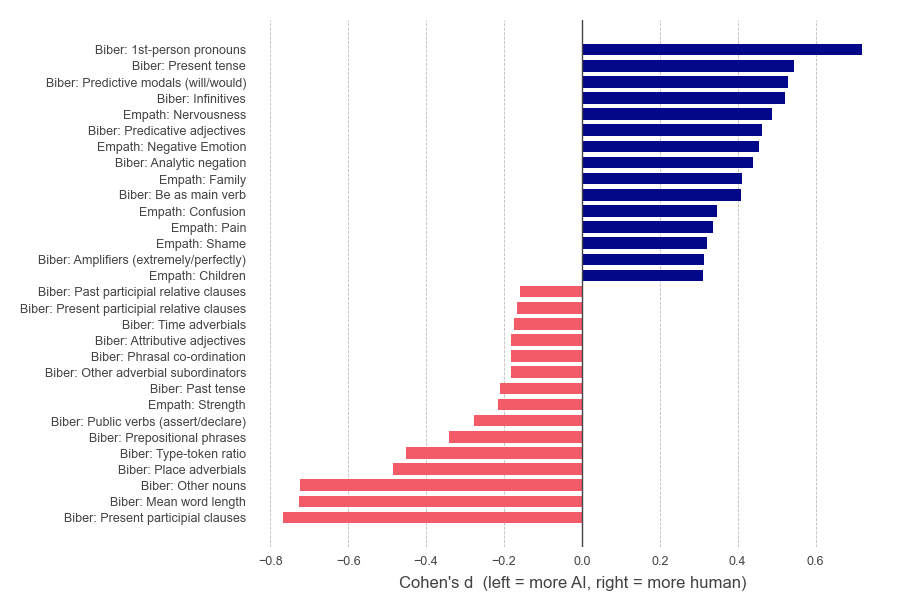

Saved plots/satellite_human_vs_ai_profile.pdf


In [10]:
####################
# Linguistic features and human-vs-AI classifier
####################
# Shared with the other study: the analysis lives in src/linguistic.py so both notebooks
# run identical code. That module's docstring lists the files it writes.

import sys
from pathlib import Path

ROOT = Path.cwd().parent
for path in (str(ROOT), str(ROOT / "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import pandas as pd
from helpers import make_aesthetic
from linguistic import run_features

TABLE_EXPORT = Path("tables")
FIGURE_EXPORT = Path("plots")
STUDY_STEM = Path.cwd().name

make_aesthetic(smallest_font_size=9, with_ticks=True)

feature_table, cv_all = run_features(
    pd.read_csv("data/clean/analysis_data.csv"),
    TABLE_EXPORT, FIGURE_EXPORT, STUDY_STEM,
)

## Keyness

**Output:** `satellite_human_ai_keyness.csv`

**Computation:** log-odds with a Dirichlet prior, human versus AI text.

Human docs: 259  |  AI docs: 259


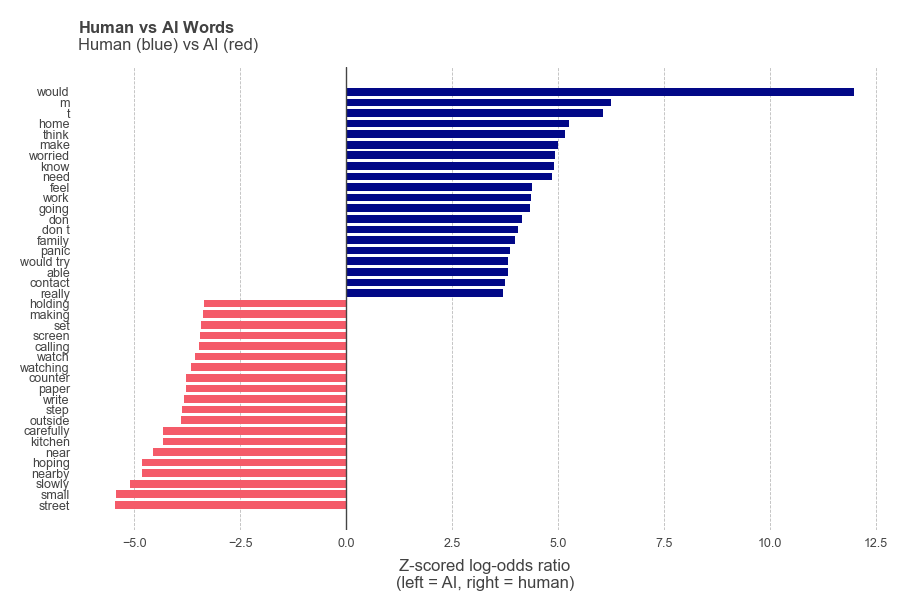

Saved plots/satellite_logodds_human_vs_ai.pdf


In [11]:
####################
# Keyness: which words distinguish human from AI text
####################
# Shared with the other study; see src/linguistic.py.

import sys
from pathlib import Path

ROOT = Path.cwd().parent
for path in (str(ROOT), str(ROOT / "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import pandas as pd
from helpers import make_aesthetic, make_bold
from linguistic import run_keyness

TABLE_EXPORT = Path("tables")
FIGURE_EXPORT = Path("plots")
STUDY_STEM = Path.cwd().name

make_aesthetic(smallest_font_size=9, with_ticks=True)

keyness_results = run_keyness(
    pd.read_csv("data/clean/analysis_data.csv"),
    TABLE_EXPORT, FIGURE_EXPORT, STUDY_STEM, make_bold,
)

# Heterogeneous treatment effects

**Outputs:** `satellite_causal_forest_blp.csv`, and `blp_*.pdf` and `loess_*.pdf` for each outcome and comparison (Supplementary Information)

**Computation:** exports the analysis sample for each comparison, then runs the causal forests in `hte_grf.R`.

In [12]:
# ─────────────────────────────────────────────
# FLAG: EXCLUSION — Heterogeneous treatment effects (HTE / GRF)
# Applied on top of main sample
#   1. Gender restricted to Male/Female (non-binary excluded as moderator
#      variable would be collinear with small cell sizes)
#   2. Listwise deletion on all moderator columns (dropna at end)
#   Treat vs placebo also requires ac_* engagement cols: participants
#   whose journal could not be matched, or who wrote fewer than 5 words,
#   have these set to NaN and are excluded from that contrast's HTE export.
# Same procedure as sci_fund_real/main_analysis.ipynb, so both studies'
# forests are fit on identically constructed inputs.
# ─────────────────────────────────────────────
import pandas as pd

hte_df = pd.read_csv("data/clean/analysis_data.csv")
# ac_prop_ai_words exceeds 1 for a handful of participants; cap it so the
# proportion is well defined wherever it is used downstream.
hte_df["ac_prop_ai_words"] = hte_df["ac_prop_ai_words"].clip(upper=1)

BASE_X_COLS = [
    "familiar", "age",
    "mi_index", "transport_index",
    "iri_fa", "iri_pc", "iri_pd",
    "rw_journal", "rw_write",
    "educ_num", "income_num", "ideology_num",
    "ai_attitude_index",
]

ENGAGEMENT_COLS = ["ac_received", "ac_acceptance_rate", "ac_total_words", "ac_prop_ai_words"]

SYS_COLS = ["sys_easy", "sys_fun", "sys_helped", "sys_tailored", "sys_realistic", "sys_agency_1"]

# treat vs placebo: base + engagement + system ratings
# treat vs vignette: base only (no autocomplete or sys ratings)
CONTRAST_X_COLS = {
    ("treat", "placebo"):  BASE_X_COLS + ENGAGEMENT_COLS + SYS_COLS,
    ("treat", "vignette"): BASE_X_COLS,
}

OUTCOMES  = ["closeness_index", "attitude_index"]
TREATMENT = "treat_status"
CONTRASTS = [("treat", "placebo"), ("treat", "vignette")]

hte_df = hte_df.loc[hte_df["demo_gender"].isin(["Male", "Female"])].copy()
hte_df["age"] = pd.to_numeric(hte_df["age"], errors="coerce")

for t1, t0 in CONTRASTS:
    x_cols    = CONTRAST_X_COLS[(t1, t0)]
    keep_cols = x_cols + OUTCOMES + [TREATMENT, "demo_gender"]

    df_r = hte_df[hte_df[TREATMENT].isin([t1, t0])][keep_cols].copy().dropna()

    print(f"\n{t1} vs {t0}: {len(df_r)} rows")
    print(df_r[TREATMENT].value_counts())
    print(f"Moderators ({len(x_cols)}): {x_cols}")

    fname = f"tables/hte_data_{t1}_vs_{t0}.csv"
    df_r.to_csv(fname, index=False)
    print(f"Saved: {fname}")



treat vs placebo: 564 rows
treat_status
treat      284
placebo    280
Name: count, dtype: int64
Moderators (23): ['familiar', 'age', 'mi_index', 'transport_index', 'iri_fa', 'iri_pc', 'iri_pd', 'rw_journal', 'rw_write', 'educ_num', 'income_num', 'ideology_num', 'ai_attitude_index', 'ac_received', 'ac_acceptance_rate', 'ac_total_words', 'ac_prop_ai_words', 'sys_easy', 'sys_fun', 'sys_helped', 'sys_tailored', 'sys_realistic', 'sys_agency_1']
Saved: tables/hte_data_treat_vs_placebo.csv

treat vs vignette: 579 rows
treat_status
vignette    295
treat       284
Name: count, dtype: int64
Moderators (13): ['familiar', 'age', 'mi_index', 'transport_index', 'iri_fa', 'iri_pc', 'iri_pd', 'rw_journal', 'rw_write', 'educ_num', 'income_num', 'ideology_num', 'ai_attitude_index']
Saved: tables/hte_data_treat_vs_vignette.csv


In [1]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-08

Description: Re-run the existing causal-forest analysis and export its results.

Inputs:
- tables/hte_data_treat_vs_placebo.csv and tables/hte_data_treat_vs_vignette.csv.
- The original study-specific R analysis.

Outputs:
- Original BLP and CATE/LOESS plots and prediction tables.
- ../satellite/tables/STUDY_causal_forest_blp.csv and run metadata.
"""
from pathlib import Path
import subprocess
import pandas as pd

STUDY = Path.cwd().name
R_SCRIPT = "hte_grf.R"
clean = pd.read_csv("data/clean/analysis_data.csv")
# ac_prop_ai_words exceeds 1 for a handful of participants; cap it so the
# proportion is well defined wherever it is used downstream.
if "ac_prop_ai_words" in clean.columns:
    clean["ac_prop_ai_words"] = clean["ac_prop_ai_words"].clip(upper=1)
clean["treat_status"] = clean.treat_status.replace({"control": "vignette"})
match_columns = ["treat_status", "closeness_index", "attitude_index"]
for control in ["placebo", "vignette"]:
    exported = pd.read_csv(f"tables/hte_data_treat_vs_{control}.csv")
    original_rows = pd.MultiIndex.from_frame(clean[match_columns].round(8))
    exported_rows = pd.MultiIndex.from_frame(exported[match_columns].round(8))
    assert exported_rows.isin(original_rows).all(), "HTE outcomes do not match the main sample."
    print(control, len(exported), exported.treat_status.value_counts().to_dict())

r_code = r'''
source("R_SCRIPT")
export_rows <- list()
for (control in names(results)) {
  for (outcome in OUTCOMES) {
    result <- results[[control]][[outcome]]
    coefficients <- result$blp
    plot_predictions <- as.data.frame(result$X_sub)
    plot_predictions$cate <- predict(result$forest)$predictions
    write.csv(plot_predictions, sprintf("tables/cate_plot_preds_treat_vs_%s_%s.csv", control, outcome), row.names = FALSE)
    export_rows[[paste(control, outcome)]] <- data.frame(
      control = control, outcome = outcome,
      term = rownames(coefficients),
      estimate = coefficients[, "Estimate"],
      se = coefficients[, "Std. Error"],
      statistic = coefficients[, "t value"],
      p = coefficients[, "Pr(>|t|)"],
      ci_lower = coefficients[, "Estimate"] - 1.96 * coefficients[, "Std. Error"],
      ci_upper = coefficients[, "Estimate"] + 1.96 * coefficients[, "Std. Error"],
      n = nrow(result$X_sub),
      n_treat = sum(result$forest$W.orig == 1),
      n_control = sum(result$forest$W.orig == 0)
    )
  }
}
write.csv(do.call(rbind, export_rows),
          "../satellite/tables/STUDY_causal_forest_blp.csv", row.names = FALSE)
capture.output(sessionInfo(), file = "../satellite/tables/STUDY_causal_forest_session.txt")
'''
r_code = r_code.replace("R_SCRIPT", R_SCRIPT).replace("STUDY", STUDY)
run = subprocess.run(["Rscript", "-e", r_code],
                     text=True, capture_output=True)
print(run.stdout)
print(run.stderr)
run.check_returncode()

placebo 564 {'treat': 284, 'placebo': 280}
vignette 579 {'vignette': 295, 'treat': 284}


Working directory: /Users/jashkina/Documents/locresearch/LocResearch/asif_studies/satellite 

--- Loading: tables/hte_data_treat_vs_placebo.csv ---
Rows: 564 

placebo   treat 
    280     284 
After dropna: 564 

Fitting: closeness_index | treat vs placebo
  n=564, T=1(treat)=284, T=0(placebo)=280

Fitting: attitude_index | treat vs placebo
  n=564, T=1(treat)=284, T=0(placebo)=280

--- Loading: tables/hte_data_treat_vs_vignette.csv ---
Rows: 579 

   treat vignette 
     284      295 
After dropna: 579 

Fitting: closeness_index | treat vs vignette
  n=579, T=1(treat)=284, T=0(vignette)=295

Fitting: attitude_index | treat vs vignette
  n=579, T=1(treat)=284, T=0(vignette)=295
Saved predictions: tables/cate_preds_treat_vs_placebo_closeness_index.csv 
Saved predictions: tables/cate_preds_treat_vs_placebo_attitude_index.csv 
Saved predictions: tables/cate_preds_treat_vs_vignette_closeness_index.csv 
Saved predictions: tables/cate_preds_treat_vs_vignette_attitude_index.csv 

Outcome: Cl